# Advective contribution to atmospheric energy budget
The atmospheric energy budget has a term related to advection, which I have previously obtained as a residual. Here, I compare this to a direct approach to calculating the advection component. The direct component has the advantage that the advection can be split up between zonal, meridional, and vertical advection.

In [1]:
import sys
import os
import inspect
from matplotlib.lines import Line2D


from isca_tools.thesis.adiabat_theory import get_temp_adiabat
from isca_tools.thesis.season_annual_harmonic import get_phase_amp
from isca_tools.thesis.surface_flux_taylor_2layer import get_sensitivity_lh
from isca_tools.utils.moist_physics import sphum_sat
from isca_tools.utils.numerical import sum_complex
from isca_tools.thesis.lapse_integral_simple import get_lnb_ind, get_temp_2_layer_approx
from isca_tools.utils.xarray import wrap_with_apply_ufunc, isel_float
from isca_tools.utils.numerical import spline_deriv_nonperiodic

# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
from isca_tools.utils.constants import kappa, L_v, c_p, c_p_ocean, rho_ocean, Stefan_Boltzmann, R, R_v, g, radius_earth, lapse_dry

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from isca_tools.plot import fig_resize, update_fontsize, update_linewidth, savefig, label_subplots
import isca_tools
from isca_tools.utils.load import load_namelist
from isca_tools.utils.base import mass_weighted_vertical_integral
# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

In [2]:
from jobs.thesis_season.publish_figs.load import smooth_n_days, get_annual_zonal_mean, spline_deriv_periodic_xr, frierson_atmospheric_heating, day_seconds, width

exp_name = 'k=1'
exp_dir = 'tau_sweep/aquaplanet/depth=1/'
exp_path = os.path.join(exp_dir, exp_name)
namelist = load_namelist(exp_path)
    
var_keep = ['ps', 't_surf', 'temp', 'height', 'sphum', 'ucomp', 'vcomp', 'omega', 'swdn_toa', 'swdn_sfc', 'lwup_sfc', 'lwdn_sfc', 'olr', 'flux_t', 'flux_lhe']
ds = isca_tools.load_dataset(os.path.join(exp_dir, exp_name), first_month_file=25)[var_keep]

# Consider only enough latitudes so compute meridional derivative
lat_target = 60
n_lat = 3
lat_selected = ds.lat.values[np.argsort(np.abs(ds.lat - lat_target))[:n_lat]]
ds = ds.sel(lat=np.sort(lat_selected))


sigma_levels_half = np.asarray(namelist['vert_coordinate_nml']['bk'])
sigma_levels_full = np.convolve(sigma_levels_half, np.ones(2) / 2, 'valid')
ds['lev_sigma'] = (ds.pfull * 0 + sigma_levels_full).squeeze()
ds.attrs['albedo'] = namelist['mixed_layer_nml']['albedo_value']
ds = ds.load()

### Direct computation
Below, I compute directly the advective terms from the horizontal and vertical derivatives. I do this on the raw daily data, before averaging over all years, and longitudes and smoothing to give the result at a given latitude shown in the plot. I plot the contributions from each method of advection, as well as the sum.

In [3]:
def horizontal_gradient(
    field: xr.DataArray,
    lon_dim: str = "lon",
    lat_dim: str = "lat",
    radius: float = radius_earth,
) -> tuple[xr.DataArray, xr.DataArray]:
    """Compute spherical horizontal gradients on the input vertical surfaces.

    Args:
        field: Field with latitude and full periodic longitude dimensions.
            Latitude and longitude coordinates must be in degrees.
        lon_dim: Longitude dimension.
        lat_dim: Latitude dimension.
        radius: Planetary radius in metres.

    Returns:
        Tuple containing eastward and northward derivatives per metre.

    Raises:
        ValueError: If coordinates are unsuitable for this discretisation.
    """
    lon = np.asarray(field[lon_dim].values, dtype=float)
    lat = np.asarray(field[lat_dim].values, dtype=float)

    if lon.size < 3 or lat.size < 3:
        raise ValueError("At least three longitude and latitude points required.")
    if not np.all(np.diff(lon) > 0) or not np.all(np.diff(lat) > 0):
        raise ValueError("Sort longitude and latitude in ascending order.")
    if np.any(np.abs(lat) >= 90):
        raise ValueError("Exclude exact poles before computing gradients.")

    dlon = np.diff(np.deg2rad(lon))
    if not np.allclose(dlon, dlon[0]):
        raise ValueError("Longitude must be regularly spaced.")
    if not np.isclose(dlon[0] * lon.size, 2 * np.pi):
        raise ValueError("Require full periodic longitude without duplicate endpoint.")

    coslat = np.cos(np.deg2rad(field[lat_dim]))

    grad_x = (
        field.roll({lon_dim: -1}, roll_coords=False)
        - field.roll({lon_dim: 1}, roll_coords=False)
    ) / (2 * dlon[0] * radius * coslat)

    grad_y = (
        field.differentiate(lat_dim, edge_order=2)
        * (180 / np.pi)
        / radius
    )

    return grad_x, grad_y


def compute_column_advection(
    temp: xr.DataArray,
    sphum: xr.DataArray,
    u: xr.DataArray,
    v: xr.DataArray,
    omega: xr.DataArray,
    geopotential: xr.DataArray,
    ps: xr.DataArray,
    sigma: xr.DataArray,
    lev_dim: str = "pfull",
    lon_dim: str = "lon",
    lat_dim: str = "lat",
    radius: float = radius_earth,
    simpson_method: bool = True,
) -> xr.Dataset:
    """Compute column pressure-coordinate moist-static-energy advection.

    Assumes pure sigma coordinates, p = sigma * ps. Outputs are positive
    for advective energy loss and have units W m-2.

    Args:
        temp: Temperature in K.
        sphum: Specific humidity in kg kg-1.
        u: Eastward wind in m s-1.
        v: Northward wind in m s-1.
        omega: Pressure velocity Dp/Dt in Pa s-1.
        geopotential: Geopotential in m2 s-2, not height in metres.
        ps: Surface pressure in Pa.
        sigma: Dimensionless full-level sigma values on lev_dim.
        lev_dim: Vertical dimension.
        lon_dim: Longitude dimension.
        lat_dim: Latitude dimension.
        radius: Planetary radius in metres.
        simpson_method: Whether to use Simpson's method for vertical integration.
            Much quicker if `False`.

    Returns:
        Dataset containing directional and total column advection.

    Raises:
        ValueError: If sigma is not a valid one-dimensional coordinate.
    """
    if sigma.dims != (lev_dim,):
        raise ValueError("sigma must have only the vertical dimension.")

    sigma_values = np.asarray(sigma.values, dtype=float)
    if (
        np.any(sigma_values <= 0)
        or np.any(sigma_values > 1)
        or not np.all(np.diff(sigma_values) > 0)
    ):
        raise ValueError("Require increasing, dimensionless sigma in (0, 1].")

    temp, sphum, u, v, omega, geopotential, ps, sigma = xr.align(
        temp, sphum, u, v, omega, geopotential, ps, sigma,
        join="exact",
    )

    h = c_p * temp + L_v * sphum + geopotential

    h_sigma = h.assign_coords({lev_dim: sigma_values})
    dh_dsigma = h_sigma.differentiate(lev_dim, edge_order=2)
    dh_dsigma = dh_dsigma.assign_coords({lev_dim: h[lev_dim]})
    dh_dp = dh_dsigma / ps

    dh_dx_sigma, dh_dy_sigma = horizontal_gradient(
        h, lon_dim, lat_dim, radius
    )
    dps_dx, dps_dy = horizontal_gradient(
        ps, lon_dim, lat_dim, radius
    )

    dh_dx_p = dh_dx_sigma - sigma * dps_dx * dh_dp
    dh_dy_p = dh_dy_sigma - sigma * dps_dy * dh_dp

    integrands = {
        "adv_zonal": u * dh_dx_p,
        "adv_meridional": v * dh_dy_p,
        "adv_vertical": omega * dh_dp,
    }

    result = xr.Dataset()
    for name, integrand in integrands.items():
        result[name] = ps * mass_weighted_vertical_integral(
            integrand,
            sigma,
            lev_dim=lev_dim,
            norm=False,
            simpson_method=simpson_method,
        )
        result[name].attrs.update(
            units="W m-2",
            sign_convention="Positive for advective energy loss",
        )

    result["adv_direct"] = (
        result.adv_zonal
        + result.adv_meridional
        + result.adv_vertical
    )
    result["adv_direct"].attrs.update(
        units="W m-2",
        sign_convention="Positive for advective energy loss",
    )

    return result

In [4]:
simpson_integ = False           # For speed make False, makes litter effect
adv = compute_column_advection(
    temp=ds.temp,
    sphum=ds.sphum,
    u=ds.ucomp,
    v=ds.vcomp,
    omega=ds.omega,                  # Verify Pa s-1.
    geopotential=g * ds.height,       # Only if height is in metres.
    ps=ds.ps,                    # Must be Pa.
    sigma=ds.lev_sigma,              # Dimensionless, not hPa.
    simpson_method=simpson_integ            
)

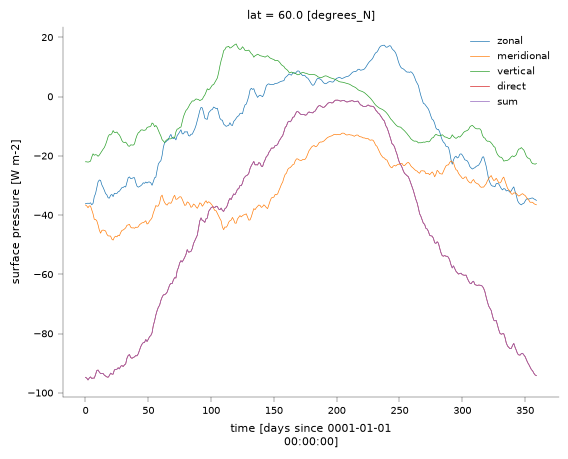

In [5]:
adv_smooth = get_annual_zonal_mean(adv.isel(lat=1), smooth_n_days=smooth_n_days)
adv_smooth['sum'] = adv_smooth.adv_zonal + adv_smooth.adv_meridional + adv_smooth.adv_vertical
for key in adv_smooth:
    adv_smooth[key].plot(label=key.replace('adv_', ''))
plt.gca().legend()
plt.show()

### Residual method
Here, I compute the advective contribution as a residual. Here I average first before computing the advective components. A slight nuance in the calculation is that the integral is defined on pressure coordinates, but I convert into an integral over sigma coordinates. To do this, need to alter the tendencies slightly to account for them being defined as on fixed pressure coordinates.

In [6]:
def sigma_derivative(
    field: xr.DataArray,
    sigma: xr.DataArray,
    lev_dim: str = "pfull",
) -> xr.DataArray:
    """Differentiate a field with respect to dimensionless sigma.

    Args:
        field: Field defined on full model levels.
        sigma: Dimensionless sigma values with dimension lev_dim.
        lev_dim: Vertical dimension.

    Returns:
        Derivative with respect to sigma, retaining the original level labels.

    Raises:
        ValueError: If sigma has incompatible dimensions or is not increasing.
    """
    if sigma.dims != (lev_dim,):
        raise ValueError("sigma must have only the vertical dimension.")

    field, sigma = xr.align(field, sigma, join="exact")
    values = np.asarray(sigma.values, dtype=float)

    if not np.all(np.diff(values) > 0):
        raise ValueError("sigma must increase monotonically.")

    result = (
        field.assign_coords({lev_dim: values})
        .differentiate(lev_dim, edge_order=2)
    )
    return result.assign_coords({lev_dim: field[lev_dim]})


ds_av = get_annual_zonal_mean(
    ds.isel(lat=1),
    smooth_n_days=smooth_n_days,
)

sigma = ds_av.lev_sigma
time_seconds = ds_av.time * day_seconds

e = c_p * ds_av.temp + L_v * ds_av.sphum

de_dt_sigma = spline_deriv_periodic_xr(time_seconds, e)
dq_dt_sigma = spline_deriv_periodic_xr(time_seconds, ds_av.sphum)
dps_dt = spline_deriv_periodic_xr(time_seconds, ds_av.ps)

de_dsigma = sigma_derivative(e, sigma)
dq_dsigma = sigma_derivative(ds_av.sphum, sigma)

# Convert fixed-sigma tendencies to fixed-pressure tendencies.
de_dt_p = (
    de_dt_sigma
    - sigma * (dps_dt / ds_av.ps) * de_dsigma
)
dq_dt_p = (
    dq_dt_sigma
    - sigma * (dps_dt / ds_av.ps) * dq_dsigma
)

ds_av["mse_tend_atmos_sigma"] = (
    ds_av.ps
    * mass_weighted_vertical_integral(
        de_dt_sigma, sigma, "pfull",
        simpson_method=True, norm=False,
    )
)

ds_av["mse_tend_atmos"] = (
    ds_av.ps
    * mass_weighted_vertical_integral(
        de_dt_p, sigma, "pfull",
        simpson_method=True, norm=False,
    )
)

ds_av["storage_coordinate_correction"] = (
    ds_av.mse_tend_atmos_sigma - ds_av.mse_tend_atmos
)

ds_av["sphum_col_tend"] = (
    ds_av.ps
    * mass_weighted_vertical_integral(
        dq_dt_p, sigma, "pfull",
        simpson_method=True, norm=False,
    )
)

ds_av["flux_atmos"] = (
    frierson_atmospheric_heating(ds_av, ds_av.albedo)
    + ds_av.flux_t
    + ds_av.flux_lhe
)

# Positive for advective energy loss. Includes the correct fixed pressure rather than sigma conversion.
ds_av["adv_atmos"] = (
    ds_av.flux_atmos - ds_av.mse_tend_atmos
)

#### Averaging last
Here I compute all the components in the energy budget from the raw data, before averaging.

In [7]:
spline_deriv_non_periodic_xr = wrap_with_apply_ufunc(
    spline_deriv_nonperiodic,
    input_core_dims=[['time'], ['time']],
    output_core_dims=[['time']])

ds_work = ds.isel(lat=1).copy()

sigma = ds_work.lev_sigma
time_seconds = ds_work.time * day_seconds

e = c_p * ds_work.temp + L_v * ds_work.sphum

de_dt_sigma = spline_deriv_non_periodic_xr(time_seconds, e)
dps_dt = spline_deriv_non_periodic_xr(time_seconds, ds_work.ps)
de_dsigma = sigma_derivative(e, sigma)

de_dt_p = (
    de_dt_sigma
    - sigma * (dps_dt / ds_work.ps) * de_dsigma
)

ds_work["mse_tend_atmos"] = (
    ds_work.ps
    * mass_weighted_vertical_integral(
        de_dt_p, sigma, "pfull",
        simpson_method=simpson_integ, norm=False,
    )
)

ds_work["flux_atmos"] = (
    frierson_atmospheric_heating(ds_work, ds_work.albedo)
    + ds_work.flux_t
    + ds_work.flux_lhe
)

ds_av2 = get_annual_zonal_mean(
    ds_work,
    smooth_n_days=smooth_n_days,
)

ds_av2["adv_atmos"] = (
    ds_av2.flux_atmos - ds_av2.mse_tend_atmos
)

### Deviation between residual and direct methodologies
Below I show that the residual methodology is pretty similar whether averaging first or second. However, there is a notable mismatch compared to the direct computation.

I also show for a single longitude and time period. Here we see the time series seem in phase and broadly consistent, just that magnitude of the directly computed values reach higher extreme values. This is apparent from the right most plot, which is for all longitudes and days at a single latitude. It shows clearly that for a given direct calculation, the residual calculation has smaller magnitude.

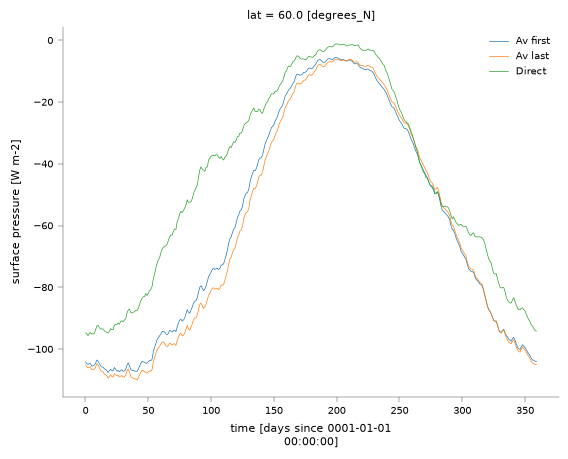

In [8]:
ds_av['adv_atmos'].plot(label='Av first')
ds_av2['adv_atmos'].plot(label='Av last')
adv_smooth['sum'].plot(label='Direct')
plt.gca().legend()
# ds_av["storage_coordinate_correction"].plot()

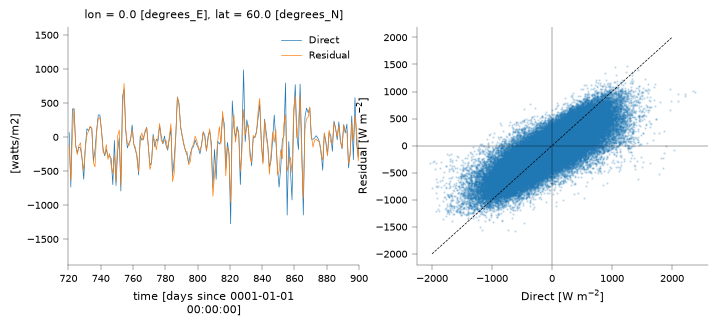

In [9]:
lon_plot = 0
fig, ax = plt.subplots(1, 2)
fig_resize(fig, width['two_col']*1.5)
adv['adv_direct'].isel(lat=1, lon=lon_plot).plot(ax=ax[0], label='Direct')
(ds_work["flux_atmos"] - ds_work["mse_tend_atmos"]).isel(lon=lon_plot).plot(ax=ax[0], label='Residual')
ax[0].set_xlim(360*2, 360*2.5)
ax[0].legend()

ax[1].set_xlabel('Direct [W m$^{-2}$]')
ax[1].set_ylabel('Residual [W m$^{-2}$]')
ax[1].scatter(adv['adv_direct'].isel(lat=1), (ds_work["flux_atmos"] - ds_work["mse_tend_atmos"]), alpha=0.2, s=0.5)
ax[1].plot([-2000, 2000], [-2000, 2000], color='k', ls='--')
ax[1].axhline(0, color='k', lw=ax_linewidth)
ax[1].axvline(0, color='k', lw=ax_linewidth)